In [1]:
import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem import AllChem

# Comparing SMILES chemical similarity

Different similarity scorings are possible. **Tanimoto chemical similarity scores** are used here MORGAN bits which are generated from stereochemical SMILES as given in the Chemical Component dictionary.

## 1. MORGAN fingerprint generator

In [2]:
# prepare a fingerprint generator
mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048, includeChirality=True)

In [3]:
canonicalAAs = ['ALA', 'ARG', 'ASN', 'ASP', 'CYS', 'GLN', 'GLU', 'GLY', 'HIS', 'ILE', 'LEU', 'LYS', 'MET', 'PHE', 'PRO', 'SER', 'THR', 'TRP', 'TYR', 'VAL']
               
canonicalAA_smiles = ['C[C@@H](C(=O)O)N', 'C(C[C@@H](C(=O)O)N)CNC(=[NH2+])N', 
                      'C([C@@H](C(=O)O)N)C(=O)N', 'C([C@@H](C(=O)O)N)C(=O)O',
                      'C([C@@H](C(=O)O)N)S', 'C(CC(=O)N)[C@@H](C(=O)O)N', 'C(CC(=O)O)[C@@H](C(=O)O)N',
                      'C(C(=O)O)N', 'c1c([nH+]c[nH]1)C[C@@H](C(=O)O)N',
                      'CC[C@H](C)[C@@H](C(=O)O)N', 'CC(C)C[C@@H](C(=O)O)N', 'C(CC[NH3+])C[C@@H](C(=O)O)N',
                      'CSCC[C@@H](C(=O)O)N', 'c1ccc(cc1)C[C@@H](C(=O)O)N', 'C1C[C@H](NC1)C(=O)O',
                      'C([C@@H](C(=O)O)N)O', 'C[C@H]([C@@H](C(=O)O)N)O',
                      'c1ccc2c(c1)c(c[nH]2)C[C@@H](C(=O)O)N', 'c1cc(ccc1C[C@@H](C(=O)O)N)O', 'CC(C)[C@@H](C(=O)O)N']

# transform SMILES into mol intermediate objects
canonicalAA_mols = [Chem.MolFromSmiles(smile) for smile in canonicalAA_smiles]

# transform mol objects into bits to compare
canonicalAA_bits = [mfpgen.GetFingerprint(mol) for mol in canonicalAA_mols]

In [4]:
canonical_df = pd.DataFrame(index=canonicalAAs)
canonical_df['SMILES'] = canonicalAA_smiles
canonical_df['MorganBITS'] = canonicalAA_bits
canonical_df

,SMILES,MorganBITS
ALA,C[C@@H](C(=O)O)N,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
ARG,C(C[C@@H](C(=O)O)N)CNC(=[NH2+])N,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
ASN,C([C@@H](C(=O)O)N)C(=O)N,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
ASP,C([C@@H](C(=O)O)N)C(=O)O,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
CYS,C([C@@H](C(=O)O)N)S,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
GLN,C(CC(=O)N)[C@@H](C(=O)O)N,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
GLU,C(CC(=O)O)[C@@H](C(=O)O)N,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
GLY,C(C(=O)O)N,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
HIS,c1c([nH+]c[nH]1)C[C@@H](C(=O)O)N,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
ILE,CC[C@H](C)[C@@H](C(=O)O)N,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."


## 2. Manual use for one molecule

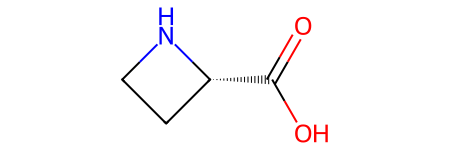

In [5]:
####################
# INPUT            #
# put search below #
####################

input_smile = 'C1CN[C@@H]1C(=O)O'   # azetidine
input_chem = Chem.MolFromSmiles(input_smile)
input_bit =  mfpgen.GetFingerprint(input_chem)
input_chem

{'ALA': 0.16666666666666666, 'ARG': 0.10526315789473684, 'ASN': 0.13793103448275862, 'ASP': 0.18518518518518517, 'CYS': 0.14285714285714285, 'GLN': 0.12903225806451613, 'GLU': 0.13333333333333333, 'GLY': 0.18181818181818182, 'HIS': 0.1282051282051282, 'ILE': 0.12903225806451613, 'LEU': 0.13333333333333333, 'LYS': 0.12121212121212122, 'MET': 0.12121212121212122, 'PHE': 0.11764705882352941, 'PRO': 0.6666666666666666, 'SER': 0.14814814814814814, 'THR': 0.14285714285714285, 'TRP': 0.11627906976744186, 'TYR': 0.1111111111111111, 'VAL': 0.14814814814814814}


<Axes: title={'center': 'Chemical Tanimoto Similarities'}>

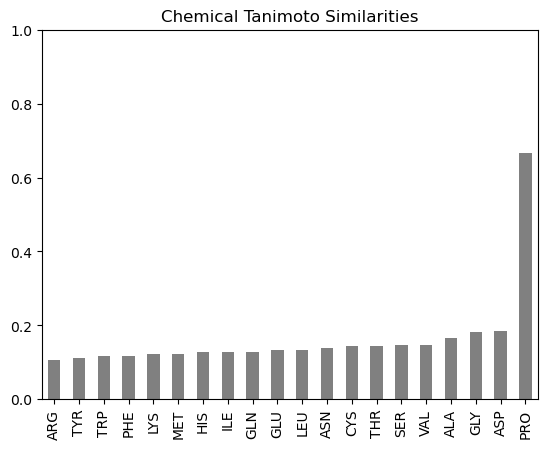

In [6]:
# loop for similarities between input and canonicals
similarities_dict = {}
for canonical_aa in canonical_df.index:
    similarities_dict[canonical_aa] = DataStructs.TanimotoSimilarity(input_bit, canonical_df['MorganBITS'][canonical_aa])

print(similarities_dict)

pd.Series(similarities_dict).sort_values().plot.bar(color='gray', title="Chemical Tanimoto Similarities", ylim=[0,1])

## 3. Automatic use for multiple molecules 

We update the MONDE$\cdot$T _tanimotoTable_ with these values. 

In [7]:
df = pd.read_csv("updated_to_1000_PDB_described_protein_2026_06_Nov-ORDERED.csv", sep=";", index_col=0)
df_noaa = df[~df['ID'].isin(canonicalAAs)]
df_noaa.to_csv("updated_to_1000_PDB_described_protein_2026_06_Nov-NCAA-ORDERED.csv", sep=";")

In [33]:
df = pd.read_csv("updated_to_1000_PDB_described_protein_2026_06_Nov-ORDERED.csv", sep=";", index_col=0)
df = df[['ID', 'SMILES']]
# generate SMILES
mols = [Chem.MolFromSmiles(smile) for smile in df.SMILES]
# generate MORGAN BITS
bits = [mfpgen.GetFingerprint(mol) if mol is not None else 'invalid_valence' for mol in mols]
df.insert(loc=df.shape[1], column="BITS", value=bits)
df

[21:11:05] Explicit valence for atom # 5 C, 6, is greater than permitted
[21:11:05] Explicit valence for atom # 1 N, 4, is greater than permitted
[21:11:05] Explicit valence for atom # 0 B, 4, is greater than permitted
[21:11:05] Explicit valence for atom # 1 As, 6, is greater than permitted


,ID,SMILES,BITS
Column1,,,
8014,6J9,c1c[nH]c2c1c(ncn2)N3CCNCC3,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
13720,A1B60,c1cc(ccc1c2ccc(cc2)OP(=O)(O)O)C(=O)O,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
13749,A1B6Z,COC(=O)CC[C@H](C(=O)OC)N,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ..."
46142,UQ4,c1cc(c2c(c1NCCC(=O)O)non2)N(=O)=O,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
21334,AZ1,C(CCCC(=O)O)CCCC(=O)O,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
...,...,...,...
52080,ZV4,c1cc(ccc1C[C@@H](C(=O)O)N)P(=O)(O)O,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
52082,ZV7,C(CN(C(=O)CCl)N)C=O,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
52185,ZYJ,COc1ccc(cc1OC)/C=N/O[C@@H]2C[C@H](NC2)C(=O)O,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."


In [34]:
for canonical_aa, canonical_smile in zip(canonicalAAs, canonicalAA_smiles):
    similarities = []

    # iterate over ncAAs and calculate the Tanimoto similarity to the canonical amino acids
    for aa, input_bit in zip(df.ID, df.BITS):
        print(aa)
        if input_bit != "invalid_valence":
            similarities.append(DataStructs.TanimotoSimilarity(input_bit, canonical_df['MorganBITS'][canonical_aa]))
        else:
            similarities.append('invalid_valence')
    df.insert(loc=df.shape[1], column=f"{canonical_aa}_similarity", value=similarities)

6J9
A1B60
A1B6Z
UQ4
AZ1
ZEU
A1APX
BF7
C0O
D0C
F9D
TDF
DHV
HVA
I2M
5OM
MV9
2LZ
7YO
A1AP1
A1E9U
A1EYU
A1I9P
A1I9S
A1JAG
A1JSS
A1KN1
A1KPW
E03
HTN
IG8
IOY
KW4
LMQ
LWI
M2S
MHE
MND
PAC
SEM
SJ2
TDD
ZUK
XDV
QOL
TBG
DTH
WFP
A1L9X
CCJ
JGO
9JC
A1H2D
A1H2E
A1IG7
A1IKE
C9T
IB9
RX9
RXL
WG0
MED
BE2
ORD
TH5
NME
DNE
DLY
2TL
AG2
HMF
DSE
DAS
2JN
VAD
LPH
ZAE
EDN
V53
U2M
API
DIL
DSG
BAL
DHI
ZCL
ZGL
28J
SOQ
ZY9
DAR
DCY
ALQ
DGN
DGL
4J2
HZP
5OH
DTY
QVS
QUJ
004
00S
02J
0A1
0AF
0QE
0TD
1ZN
2MR
3FG
48V
4BF
4D4
4HH
5CT
5F0
5SQ
6V1
9IJ
ABA
AC5
ACB
ACE
ACY
AGM
AIB
ALA
ALC
ALN
ALO
ALY
AME
AR7
ARG
ASA
ASJ
ASN
ASP
ASX
AYA
AYE
B3A
B3D
B3E
B3K
B3L
B3Q
BB9
BEZ
BIF
BIL
BMT
BOC
BP5
CAF
CAS
CCS
CF0
CGU
CH6
CIR
CME
CMT
CR2
CR8
CRF
CRO
CRQ
CSD
CSO
CSS
CSU
CSX
CXM
CY3
CYG
CYS
D2T
DAB
DAH
DAL
DAM
DBB
DBU
DDE
DDZ
DHA
DIV
DLE
DPN
DPP
DPR
DSN
DTR
DVA
DYA
EEP
ELY
ETA
FGA
FME
FTR
FVA
GGL
GHP
GL3
GLN
GLU
GLY
GLZ
GYC
GYS
HIC
HIP
HIS
HMR
HRG
HY3
HYP
I6W
I77
IAS
IIL
ILE
ILX
IML
IVA
IYR
KBE
KCR
KCX
KPI
LE1
LEU
LLP
LYR
LYS
LYZ
M3L
MAA
MD

In [35]:
df

,ID,SMILES,BITS,ALA_similarity,ARG_similarity,ASN_similarity,ASP_similarity,CYS_similarity,GLN_similarity,GLU_similarity,...,LEU_similarity,LYS_similarity,MET_similarity,PHE_similarity,PRO_similarity,SER_similarity,THR_similarity,TRP_similarity,TYR_similarity,VAL_similarity
Column1,,,,,,,,,,,,,,,,,,,,,
8014,6J9,c1c[nH]c2c1c(ncn2)N3CCNCC3,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.02381,0.036364,0.021277,0.021739,0.021739,0.020408,0.020833,...,0.020833,0.019608,0.019608,0.081633,0.06383,0.022222,0.021739,0.125,0.078431,0.022222
13720,A1B60,c1cc(ccc1c2ccc(cc2)OP(=O)(O)O)C(=O)O,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.117647,0.083333,0.102564,0.105263,0.105263,0.097561,0.1,...,0.1,0.093023,0.093023,0.170732,0.097561,0.108108,0.105263,0.137255,0.162791,0.108108
13749,A1B6Z,COC(=O)CC[C@H](C(=O)OC)N,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",0.25,0.225,0.212121,0.21875,0.258065,0.272727,0.28125,...,0.242424,0.222222,0.257143,0.184211,0.076923,0.225806,0.21875,0.145833,0.175,0.225806
46142,UQ4,c1cc(c2c(c1NCCC(=O)O)non2)N(=O)=O,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.086957,0.122807,0.1,0.125,0.102041,0.117647,0.166667,...,0.098039,0.092593,0.092593,0.153846,0.075472,0.104167,0.08,0.129032,0.148148,0.081633
21334,AZ1,C(CCCC(=O)O)CCCC(=O)O,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.2,0.1875,0.208333,0.272727,0.217391,0.24,0.363636,...,0.2,0.222222,0.178571,0.172414,0.148148,0.227273,0.166667,0.128205,0.16129,0.173913
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52080,ZV4,c1cc(ccc1C[C@@H](C(=O)O)N)P(=O)(O)O,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.25,0.255814,0.323529,0.333333,0.257143,0.305556,0.314286,...,0.314286,0.289474,0.289474,0.612903,0.093023,0.34375,0.222222,0.363636,0.625,0.228571
52082,ZV7,C(CN(C(=O)CCl)N)C=O,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.129032,0.139535,0.142857,0.147059,0.147059,0.135135,0.138889,...,0.138889,0.157895,0.128205,0.125,0.076923,0.151515,0.114286,0.1,0.119048,0.117647
52185,ZYJ,COc1ccc(cc1OC)/C=N/O[C@@H]2C[C@H](NC2)C(=O)O,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.098039,0.076923,0.089286,0.071429,0.071429,0.086207,0.068966,...,0.107143,0.065574,0.083333,0.118644,0.211538,0.072727,0.090909,0.151515,0.114754,0.092593


In [36]:
df = df.drop(["BITS"], axis=1)

numeric_cols = ['ALA_similarity', 'ARG_similarity', 'ASN_similarity',
       'ASP_similarity', 'CYS_similarity', 'GLN_similarity', 'GLU_similarity',
       'GLY_similarity', 'HIS_similarity', 'ILE_similarity', 'LEU_similarity',
       'LYS_similarity', 'MET_similarity', 'PHE_similarity', 'PRO_similarity',
       'SER_similarity', 'THR_similarity', 'TRP_similarity', 'TYR_similarity',
       'VAL_similarity']
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')


# NEW: ADD MOST SIMILAR PARENT
names = [name for name in df[numeric_cols].idxmax(axis=1)]
parents = []

for name in names:
    try:
        parents.append(name.split("_")[0])
    except:
        parents.append(None)
        
df.insert(2, "MOST SIMILAR", parents) 
df[numeric_cols] = df[numeric_cols].round(3)
df

C:\Users\Alexandra\AppData\Local\Temp\ipykernel_35188\2176161492.py:13: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  names = [name for name in df[numeric_cols].idxmax(axis=1)]


,ID,SMILES,MOST SIMILAR,ALA_similarity,ARG_similarity,ASN_similarity,ASP_similarity,CYS_similarity,GLN_similarity,GLU_similarity,...,LEU_similarity,LYS_similarity,MET_similarity,PHE_similarity,PRO_similarity,SER_similarity,THR_similarity,TRP_similarity,TYR_similarity,VAL_similarity
Column1,,,,,,,,,,,,,,,,,,,,,
8014,6J9,c1c[nH]c2c1c(ncn2)N3CCNCC3,TRP,0.024,0.036,0.021,0.022,0.022,0.020,0.021,...,0.021,0.020,0.020,0.082,0.064,0.022,0.022,0.125,0.078,0.022
13720,A1B60,c1cc(ccc1c2ccc(cc2)OP(=O)(O)O)C(=O)O,PHE,0.118,0.083,0.103,0.105,0.105,0.098,0.100,...,0.100,0.093,0.093,0.171,0.098,0.108,0.105,0.137,0.163,0.108
13749,A1B6Z,COC(=O)CC[C@H](C(=O)OC)N,GLU,0.250,0.225,0.212,0.219,0.258,0.273,0.281,...,0.242,0.222,0.257,0.184,0.077,0.226,0.219,0.146,0.175,0.226
46142,UQ4,c1cc(c2c(c1NCCC(=O)O)non2)N(=O)=O,GLU,0.087,0.123,0.100,0.125,0.102,0.118,0.167,...,0.098,0.093,0.093,0.154,0.075,0.104,0.080,0.129,0.148,0.082
21334,AZ1,C(CCCC(=O)O)CCCC(=O)O,GLY,0.200,0.188,0.208,0.273,0.217,0.240,0.364,...,0.200,0.222,0.179,0.172,0.148,0.227,0.167,0.128,0.161,0.174
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52080,ZV4,c1cc(ccc1C[C@@H](C(=O)O)N)P(=O)(O)O,TYR,0.250,0.256,0.324,0.333,0.257,0.306,0.314,...,0.314,0.289,0.289,0.613,0.093,0.344,0.222,0.364,0.625,0.229
52082,ZV7,C(CN(C(=O)CCl)N)C=O,GLY,0.129,0.140,0.143,0.147,0.147,0.135,0.139,...,0.139,0.158,0.128,0.125,0.077,0.152,0.114,0.100,0.119,0.118
52185,ZYJ,COc1ccc(cc1OC)/C=N/O[C@@H]2C[C@H](NC2)C(=O)O,PRO,0.098,0.077,0.089,0.071,0.071,0.086,0.069,...,0.107,0.066,0.083,0.119,0.212,0.073,0.091,0.152,0.115,0.093


In [37]:
df.to_csv("tanimoto_similarity-Nov-2026.csv", sep=";", index=False)  # this needs to go into the folder "aaontology" in the webstack